# 01 — Data preparation
Goal: turn the raw hourly traffic file into a clean table with one value per cell per day.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
PROJECT = Path("..")
RAW = PROJECT / "data" / "raw" / "traffic_density_202410.csv"
PROCESSED = PROJECT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

print("Raw file exists:", RAW.exists())
print("Full path:", RAW.resolve())

Raw file exists: True
Full path: /Users/saynasarvar/city-focus/data/raw/traffic_density_202410.csv


In [6]:
df = pd.read_csv(RAW, dtype={"GEOHASH": "string"})
print(df.shape)
df.head()

(1769643, 8)


,DATE_TIME,LATITUDE,LONGITUDE,GEOHASH,MINIMUM_SPEED,MAXIMUM_SPEED,AVERAGE_SPEED,NUMBER_OF_VEHICLES
0,2024-10-01 00:00:00,41.042175,28.921509,sxk96p,6,59,33,25
1,2024-10-01 00:00:00,41.097107,28.789673,sxk3z1,9,95,47,26
2,2024-10-01 00:00:00,41.091614,28.361206,sxk1v2,55,125,84,39
3,2024-10-01 00:00:00,40.992737,28.800659,sxk3pq,32,127,62,28
4,2024-10-01 00:00:00,40.981750,28.734741,sxk3ju,7,117,50,139


In [7]:
df.dtypes

DATE_TIME                     object
LATITUDE                     float64
LONGITUDE                    float64
GEOHASH               string[python]
MINIMUM_SPEED                  int64
MAXIMUM_SPEED                  int64
AVERAGE_SPEED                  int64
NUMBER_OF_VEHICLES             int64
dtype: object

## Step 2 — Time columns
Convert DATE_TIME from text to datetime, then add DAY, HOUR and WEEKDAY.

In [8]:
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")

print(df["DATE_TIME"].dtype)
print("First:", df["DATE_TIME"].min())
print("Last: ", df["DATE_TIME"].max())

datetime64[ns]
First: 2024-10-01 00:00:00
Last:  2024-10-31 23:00:00


In [9]:
df["DAY"] = df["DATE_TIME"].dt.normalize()
df["HOUR"] = df["DATE_TIME"].dt.hour
df["WEEKDAY"] = df["DATE_TIME"].dt.dayofweek
df["DAY_NAME"] = df["DATE_TIME"].dt.day_name()

df[["DATE_TIME", "DAY", "HOUR", "WEEKDAY", "DAY_NAME"]].head()

,DATE_TIME,DAY,HOUR,WEEKDAY,DAY_NAME
0,2024-10-01,2024-10-01,0,1,Tuesday
1,2024-10-01,2024-10-01,0,1,Tuesday
2,2024-10-01,2024-10-01,0,1,Tuesday
3,2024-10-01,2024-10-01,0,1,Tuesday
4,2024-10-01,2024-10-01,0,1,Tuesday


In [10]:
per_day = df.groupby("DAY").agg(
    hours=("HOUR", "nunique"),
    rows=("GEOHASH", "size"),
    name=("DAY_NAME", "first"),
)
per_day

,hours,rows,name
DAY,,,
2024-10-01,24,57145,Tuesday
2024-10-02,24,57180,Wednesday
2024-10-03,24,57187,Thursday
2024-10-04,24,57043,Friday
2024-10-05,24,57250,Saturday
2024-10-06,24,56978,Sunday
2024-10-07,24,57124,Monday
2024-10-08,24,57320,Tuesday
2024-10-09,24,57221,Wednesday


In [11]:
per_day["is_weekday"] = per_day.index.dayofweek < 5
per_day["is_weekday"].value_counts()

is_weekday
True     23
False     8
Name: count, dtype: int64

In [12]:
oct10 = df[df["DAY"] == "2024-10-10"].groupby("HOUR").size()
normal = df[df["DAY"] == "2024-10-17"].groupby("HOUR").size()

compare = pd.DataFrame({"oct_10": oct10, "oct_17": normal})
compare["difference"] = compare["oct_10"] - compare["oct_17"]
compare

,oct_10,oct_17,difference
HOUR,,,
0,2361,2361,0
1,2289,2336,-47
2,2280,2296,-16
3,2312,2288,24
4,2317,2307,10
5,2345,2344,1
6,2398,2400,-2
7,2406,2411,-5
8,2411,2415,-4


In [13]:
num_cols = ["MINIMUM_SPEED", "MAXIMUM_SPEED", "AVERAGE_SPEED", "NUMBER_OF_VEHICLES"]
df[num_cols].describe().round(1)

,MINIMUM_SPEED,MAXIMUM_SPEED,AVERAGE_SPEED,NUMBER_OF_VEHICLES
count,1769643.0,1769643.0,1769643.0,1769643.0
mean,22.7,102.6,56.4,113.9
std,24.3,37.3,26.2,143.9
min,1.0,1.0,1.0,1.0
25%,3.0,72.0,33.0,22.0
50%,10.0,101.0,54.0,62.0
75%,42.0,131.0,80.0,147.0
max,199.0,250.0,199.0,1679.0


In [14]:
checks = pd.Series({
    "average speed > 150 km/h":    (df["AVERAGE_SPEED"] > 150).mean(),
    "average speed == 0":          (df["AVERAGE_SPEED"] == 0).mean(),
    "min speed > max speed":       (df["MINIMUM_SPEED"] > df["MAXIMUM_SPEED"]).mean(),
    "average outside [min, max]":  ((df["AVERAGE_SPEED"] < df["MINIMUM_SPEED"]) |
                                    (df["AVERAGE_SPEED"] > df["MAXIMUM_SPEED"])).mean(),
    "fewer than 5 vehicles":       (df["NUMBER_OF_VEHICLES"] < 5).mean(),
})
(checks * 100).round(2).astype(str) + " %"

average speed > 150 km/h       0.0 %
average speed == 0             0.0 %
min speed > max speed          0.0 %
average outside [min, max]     0.0 %
fewer than 5 vehicles         6.42 %
dtype: object

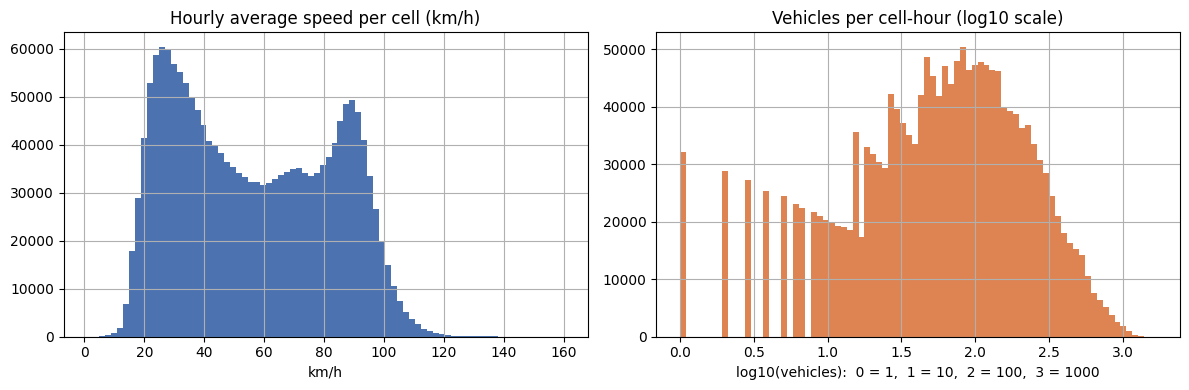

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["AVERAGE_SPEED"].clip(upper=160).hist(bins=80, ax=axes[0], color="#4C72B0")
axes[0].set_title("Hourly average speed per cell (km/h)")
axes[0].set_xlabel("km/h")

np.log10(df["NUMBER_OF_VEHICLES"]).hist(bins=80, ax=axes[1], color="#DD8452")
axes[1].set_title("Vehicles per cell-hour (log10 scale)")
axes[1].set_xlabel("log10(vehicles):  0 = 1,  1 = 10,  2 = 100,  3 = 1000")

plt.tight_layout()
plt.show()

## Step 4 — Cleaning decisions
Check exactly how many rows each rule affects, especially inside the evening window, then apply the rules.

In [16]:
print("Rows with average speed > 150:", (df["AVERAGE_SPEED"] > 150).sum())
print("Rows with average speed > 130:", (df["AVERAGE_SPEED"] > 130).sum())
print("Rows with fewer than 5 vehicles:", (df["NUMBER_OF_VEHICLES"] < 5).sum())

Rows with average speed > 150: 49
Rows with average speed > 130: 422
Rows with fewer than 5 vehicles: 113575


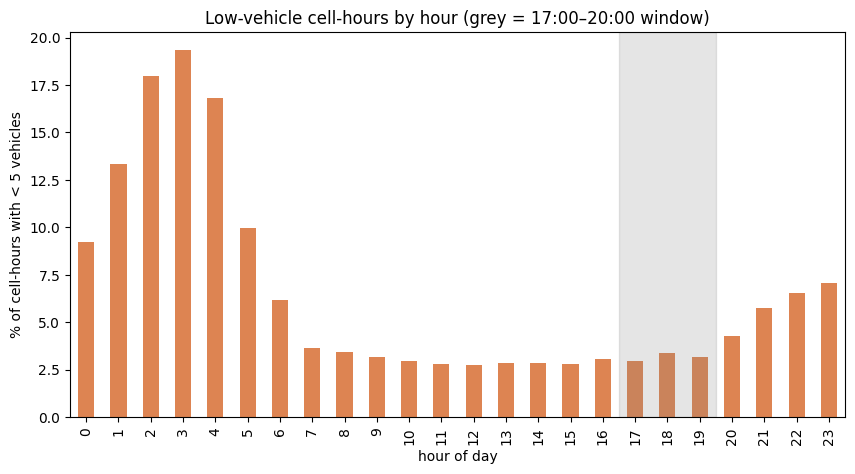

Inside the evening window: 3.17 %


In [17]:
low = df["NUMBER_OF_VEHICLES"] < 5
share_by_hour = low.groupby(df["HOUR"]).mean() * 100

ax = share_by_hour.plot(kind="bar", color="#DD8452")
ax.axvspan(16.5, 19.5, color="grey", alpha=0.2)
ax.set_xlabel("hour of day")
ax.set_ylabel("% of cell-hours with < 5 vehicles")
ax.set_title("Low-vehicle cell-hours by hour (grey = 17:00–20:00 window)")
plt.show()

print("Inside the evening window:", round(share_by_hour.loc[17:19].mean(), 2), "%")

In [18]:
evening = df["HOUR"].between(17, 19) & (df["WEEKDAY"] < 5)

low_by_cell = (df[evening]
               .groupby("GEOHASH")["NUMBER_OF_VEHICLES"]
               .apply(lambda s: (s < 5).mean()))

print("Cells where more than half of evening hours have < 5 vehicles:",
      (low_by_cell > 0.5).sum())
low_by_cell.describe().round(3)

Cells where more than half of evening hours have < 5 vehicles: 109


count    2453.000
mean        0.048
std         0.188
min         0.000
25%         0.000
50%         0.000
75%         0.000
max         1.000
Name: NUMBER_OF_VEHICLES, dtype: float64

In [19]:
MIN_VEHICLES = 5
MAX_AVG_SPEED = 150

before = len(df)
clean = df[(df["NUMBER_OF_VEHICLES"] >= MIN_VEHICLES) &
           (df["AVERAGE_SPEED"] <= MAX_AVG_SPEED)].copy()

print(f"Rows before: {before:,}")
print(f"Rows after:  {len(clean):,}")
print(f"Removed:     {before - len(clean):,}  ({(before - len(clean)) / before:.2%})")
print("Cells before:", df["GEOHASH"].nunique(), "| after:", clean["GEOHASH"].nunique())

Rows before: 1,769,643
Rows after:  1,656,068
Removed:     113,575  (6.42%)
Cells before: 2458 | after: 2415


### Cleaning decisions (data quality notes)
- File: October 2024, 1,769,643 rows, 2,458 geohash-6 cells, all 744 hours present.
- 10 Oct 10:00: data outage (35 cells instead of ~2,400). Outside the 17–20 window, no action.
- No impossible values (min > max, average outside [min, max]) were found.
- Rule 1: drop cell-hours with fewer than 5 vehicles (averages from 1–4 cars are too noisy). Removes __ % of rows, __ % inside the evening window.
- Rule 2: drop cell-hours with average speed above 150 km/h (likely errors). Removes __ rows.
- MAXIMUM_SPEED reaches 250 km/h, but we only use AVERAGE_SPEED.
- Speed distribution is bimodal (~25–30 km/h streets, ~85–90 km/h highways).

## Step 5 — Choosing the time window
Check the daily rhythm and find the hours where areas differ the most.

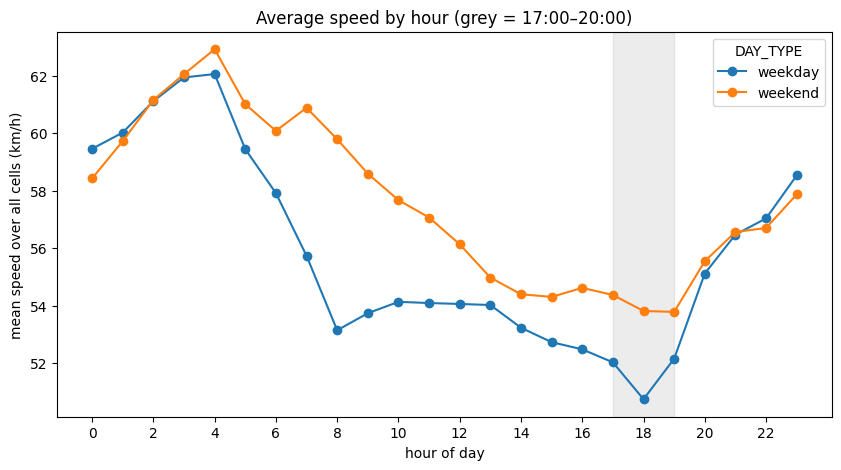

HOUR,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
DAY_TYPE,,,,,,,,,,,,,,,,,,,,,
weekday,59.5,60.0,61.1,61.9,62.1,59.4,57.9,55.7,53.1,53.7,...,53.2,52.7,52.5,52.0,50.8,52.2,55.1,56.5,57.0,58.5
weekend,58.4,59.7,61.2,62.1,62.9,61.0,60.1,60.9,59.8,58.6,...,54.4,54.3,54.6,54.4,53.8,53.8,55.6,56.6,56.7,57.9


In [20]:
clean["DAY_TYPE"] = np.where(clean["WEEKDAY"] < 5, "weekday", "weekend")

rhythm = clean.groupby(["DAY_TYPE", "HOUR"])["AVERAGE_SPEED"].mean().unstack("DAY_TYPE")

ax = rhythm.plot(marker="o")
ax.axvspan(17, 19, color="grey", alpha=0.15)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_ylabel("mean speed over all cells (km/h)")
ax.set_title("Average speed by hour (grey = 17:00–20:00)")
plt.show()

rhythm.round(1).T

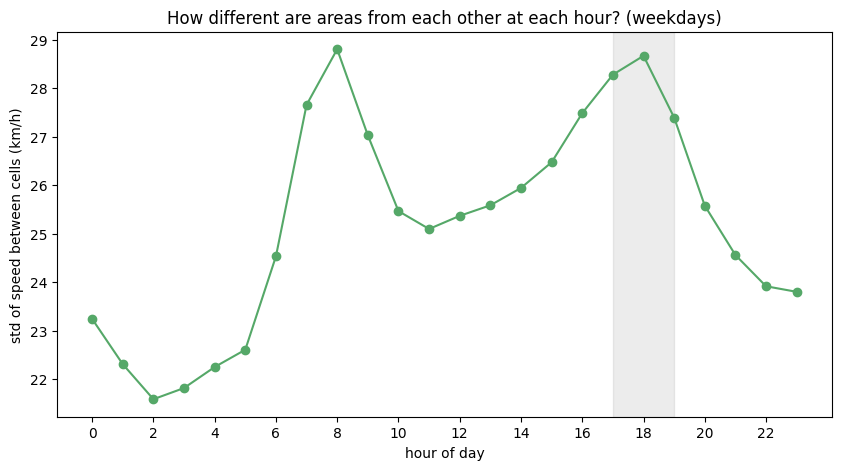

HOUR,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
std_between_cells,23.2,22.3,21.6,21.8,22.2,22.6,24.5,27.7,28.8,27.0,...,25.9,26.5,27.5,28.3,28.7,27.4,25.6,24.6,23.9,23.8
p90_minus_p10,61.6,59.1,56.5,57.4,58.7,60.0,64.8,73.1,75.9,71.7,...,69.8,70.4,72.9,75.0,76.1,72.7,68.5,65.7,64.1,63.2


In [22]:
weekday = clean[clean["WEEKDAY"] < 5]

cell_hour = weekday.groupby(["HOUR", "GEOHASH"])["AVERAGE_SPEED"].mean()
spread = cell_hour.groupby("HOUR").agg(["std", lambda s: s.quantile(0.9) - s.quantile(0.1)])
spread.columns = ["std_between_cells", "p90_minus_p10"]

ax = spread["std_between_cells"].plot(marker="o", color="#55A868")
ax.axvspan(17, 19, color="grey", alpha=0.15)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_ylabel("std of speed between cells (km/h)")
ax.set_title("How different are areas from each other at each hour? (weekdays)")
plt.show()

spread.round(1).T

In [23]:
WINDOW_HOURS = [17, 18, 19]   # change only if Cells 22–23 point elsewhere

print("Mean weekday speed in window:", round(rhythm.loc[WINDOW_HOURS, "weekday"].mean(), 1), "km/h")
print("Mean weekday speed overall:  ", round(rhythm["weekday"].mean(), 1), "km/h")
print("Between-cell std in window:  ", round(spread.loc[WINDOW_HOURS, "std_between_cells"].mean(), 1), "km/h")
print("Between-cell std overall:    ", round(spread["std_between_cells"].mean(), 1), "km/h")

Mean weekday speed in window: 51.6 km/h
Mean weekday speed overall:   55.9 km/h
Between-cell std in window:   28.1 km/h
Between-cell std overall:     25.2 km/h


## Step 6 — The cell × day table
One value per cell per weekday: mean AVERAGE_SPEED over 17:00–20:00.

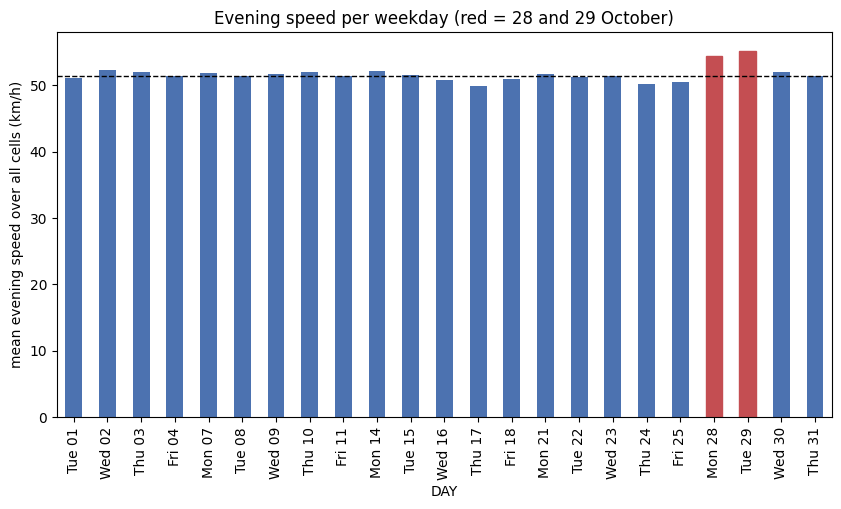

Median weekday: 51.4
DAY
2024-10-28    54.4
2024-10-29    55.2
Name: AVERAGE_SPEED, dtype: float64


In [24]:
in_window = clean["HOUR"].isin(WINDOW_HOURS) & (clean["WEEKDAY"] < 5)

day_speed = (clean[in_window]
             .groupby("DAY")["AVERAGE_SPEED"].mean()
             .round(1))

ax = day_speed.plot(kind="bar", color="#4C72B0")
for i, d in enumerate(day_speed.index):
    if d.strftime("%m-%d") in ["10-28", "10-29"]:
        ax.patches[i].set_color("#C44E52")
ax.axhline(day_speed.median(), color="black", ls="--", lw=1)
ax.set_xticklabels([d.strftime("%a %d") for d in day_speed.index], rotation=90)
ax.set_ylabel("mean evening speed over all cells (km/h)")
ax.set_title("Evening speed per weekday (red = 28 and 29 October)")
plt.show()

print("Median weekday:", day_speed.median())
print(day_speed.loc["2024-10-28":"2024-10-29"])

In [29]:
EXCLUDE_DAYS = pd.to_datetime(["2024-10-28", "2024-10-29"])   # add "2024-10-28" if Cell 26 shows it is unusual

win = clean[in_window & ~clean["DAY"].isin(EXCLUDE_DAYS)].copy()

print(f"Rows in window: {len(win):,}")
print("Evidence days:", win["DAY"].nunique())
print("Cells:", win["GEOHASH"].nunique())

Rows in window: 147,096
Evidence days: 21
Cells: 2406


In [30]:
daily_long = (win.groupby(["GEOHASH", "DAY"])
                 .agg(speed=("AVERAGE_SPEED", "mean"),
                      n_hours=("HOUR", "size"))
                 .reset_index())

daily = daily_long.pivot(index="GEOHASH", columns="DAY", values="speed")

print("Table shape (cells, days):", daily.shape)
daily.iloc[:5, :6].round(1)

Table shape (cells, days): (2406, 21)


DAY,2024-10-01,2024-10-02,2024-10-03,2024-10-04,2024-10-07,2024-10-08
GEOHASH,,,,,,
sx7chk,88.7,89.3,86.7,85.0,84.3,84.0
sx7chm,69.0,70.3,72.7,71.0,72.0,70.0
sx7cht,32.0,32.0,34.3,33.0,32.3,32.0
sx7chw,69.7,72.0,71.3,71.0,66.7,66.3
sx7chx,74.3,76.3,75.0,75.3,70.0,70.0


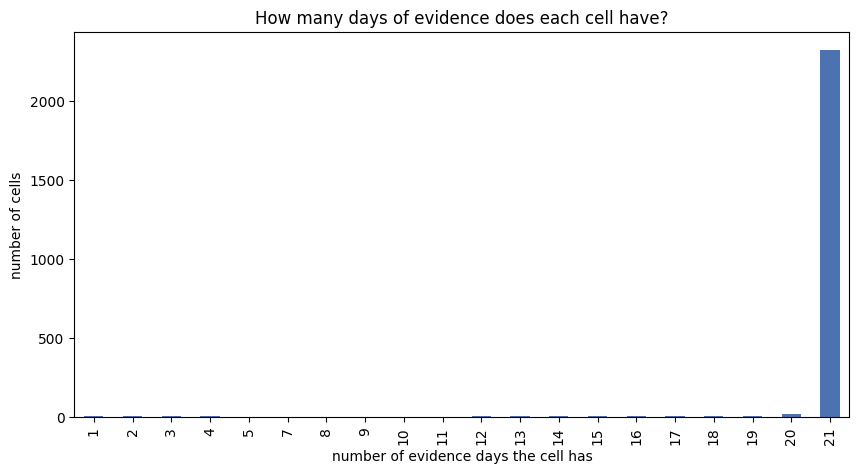

Cells with >= 22 days: 0
Cells with >= 20 days: 2337
Cells with >= 15 days: 2363
Cells with >= 10 days: 2377
Cells with >=  5 days: 2383

How many evening hours per daily value:
n_hours
1      670
2      913
3    48200
Name: count, dtype: int64


In [31]:
days_per_cell = daily.notna().sum(axis=1)

ax = days_per_cell.value_counts().sort_index().plot(kind="bar", color="#4C72B0")
ax.set_xlabel("number of evidence days the cell has")
ax.set_ylabel("number of cells")
ax.set_title("How many days of evidence does each cell have?")
plt.show()

for k in [22, 20, 15, 10, 5]:
    print(f"Cells with >= {k:2d} days: {(days_per_cell >= k).sum()}")

print("\nHow many evening hours per daily value:")
print(daily_long["n_hours"].value_counts().sort_index())

## Step 7 — Final table, noise check, save
Choose the minimum number of days, measure day-to-day noise per cell, save the outputs.

In [32]:
MIN_DAYS = 15

days_per_cell = daily.notna().sum(axis=1)
enough = days_per_cell >= MIN_DAYS

print(f"Cells with >= {MIN_DAYS} of {daily.shape[1]} days: {enough.sum()}  (kept for analysis)")
print(f"Cells with fewer days: {(~enough).sum()}  (shown as 'no data' on the map)")

Cells with >= 15 of 21 days: 2363  (kept for analysis)
Cells with fewer days: 43  (shown as 'no data' on the map)


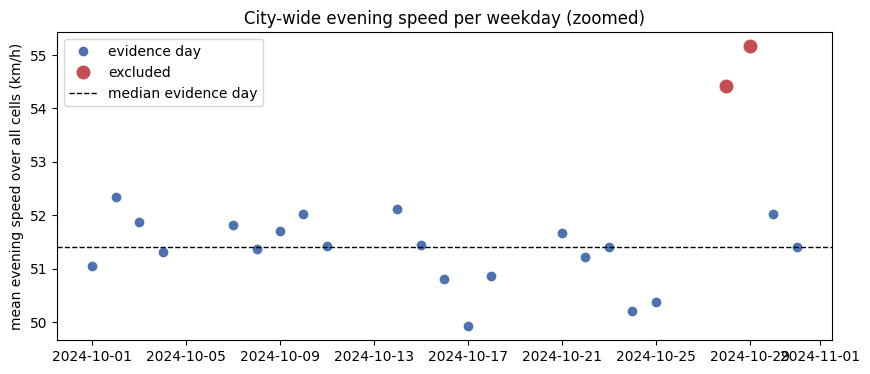

In [33]:
in_window_all = clean["HOUR"].isin(WINDOW_HOURS) & (clean["WEEKDAY"] < 5)
city_day = clean[in_window_all].groupby("DAY")["AVERAGE_SPEED"].mean()

excluded = city_day.index.isin(EXCLUDE_DAYS)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(city_day.index[~excluded], city_day[~excluded], "o", color="#4C72B0", label="evidence day")
ax.plot(city_day.index[excluded], city_day[excluded], "o", color="#C44E52", ms=9, label="excluded")
ax.axhline(city_day[~excluded].median(), color="black", ls="--", lw=1, label="median evidence day")
ax.set_ylabel("mean evening speed over all cells (km/h)")
ax.set_title("City-wide evening speed per weekday (zoomed)")
ax.legend()
plt.show()

Day-to-day std per cell (km/h):
count    2363.00
mean        2.90
std         2.45
min         0.30
25%         1.30
50%         2.06
75%         3.60
max        19.54
dtype: float64


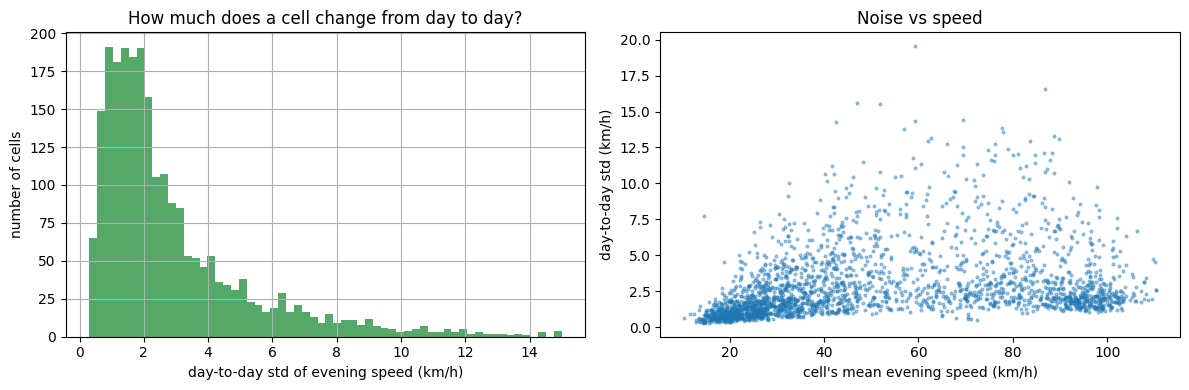

In [34]:
kept = daily[enough]

cell_mean = kept.mean(axis=1)
cell_std = kept.std(axis=1)

print("Day-to-day std per cell (km/h):")
print(cell_std.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cell_std.clip(upper=15).hist(bins=60, ax=axes[0], color="#55A868")
axes[0].set_xlabel("day-to-day std of evening speed (km/h)")
axes[0].set_ylabel("number of cells")
axes[0].set_title("How much does a cell change from day to day?")

axes[1].scatter(cell_mean, cell_std, s=4, alpha=0.4)
axes[1].set_xlabel("cell's mean evening speed (km/h)")
axes[1].set_ylabel("day-to-day std (km/h)")
axes[1].set_title("Noise vs speed")

plt.tight_layout()
plt.show()

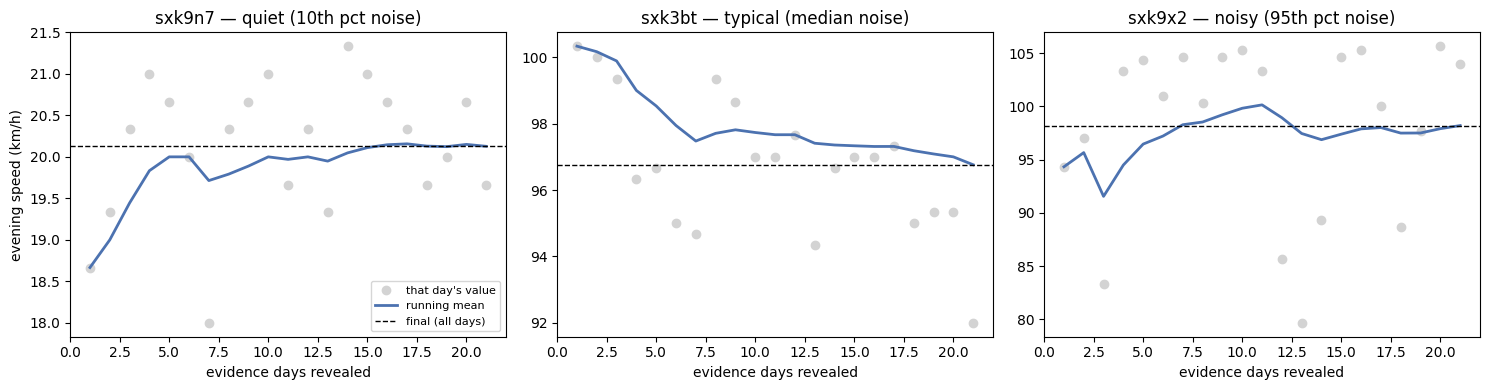

In [35]:
q = cell_std.quantile([0.10, 0.50, 0.95])
examples = [(cell_std - v).abs().idxmin() for v in q]
labels = ["quiet (10th pct noise)", "typical (median noise)", "noisy (95th pct noise)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cell, label in zip(axes, examples, labels):
    vals = kept.loc[cell]
    running = vals.expanding().mean()
    x = range(1, len(vals) + 1)
    ax.plot(x, vals.values, "o", color="lightgrey", label="that day's value")
    ax.plot(x, running.values, color="#4C72B0", lw=2, label="running mean")
    ax.axhline(vals.mean(), color="black", ls="--", lw=1, label="final (all days)")
    ax.set_title(f"{cell} — {label}")
    ax.set_xlabel("evidence days revealed")
axes[0].set_ylabel("evening speed (km/h)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [36]:
cell_info = (clean.groupby("GEOHASH")
                  .agg(lat=("LATITUDE", "first"), lon=("LONGITUDE", "first"))
                  .reindex(daily.index))
cell_info["evidence_days"] = days_per_cell
cell_info["enough_days"] = enough
cell_info["final_mean"] = daily.mean(axis=1)
cell_info["day_std"] = daily.std(axis=1)

daily_out = daily.copy()
daily_out.columns = [d.strftime("%Y-%m-%d") for d in daily_out.columns]

daily_out.to_parquet(PROCESSED / "daily_evening.parquet")
cell_info.to_csv(PROCESSED / "cells.csv")

print("Saved daily table:", daily_out.shape)
print("Saved cell info:  ", cell_info.shape)
cell_info.head()

Saved daily table: (2406, 21)
Saved cell info:   (2406, 6)


,lat,lon,evidence_days,enough_days,final_mean,day_std
GEOHASH,,,,,,
sx7chk,40.981750,27.965698,21,True,85.634921,1.974574
sx7chm,40.987244,27.965698,21,True,70.380952,2.189078
sx7cht,40.987244,27.976685,21,True,33.873016,1.593306
sx7chw,40.992737,27.976685,21,True,68.523810,3.052452
sx7chx,40.998230,27.976685,21,True,72.777778,3.026427


### Summary
- Window: weekdays 17:00–20:00 (deepest speed dip at 18:00; between-area spread 28.1 vs 25.2 km/h overall).
- Excluded days: 28 Oct (half day, 54.4 km/h) and 29 Oct (Republic Day, 55.2 km/h) vs median 51.4.
- Evidence: 21 days × 2,406 cells; one value per cell per day (mean of up to 3 evening hours).
- Cells with ≥ 15 days: ____ (rest = "no data").
- Day-to-day noise per cell: median ____ km/h, 95th percentile ____ km/h.
- Outputs: data/processed/daily_evening.parquet, data/processed/cells.csv
- Finding 1: slow, congested cells (< 30 km/h) are the most predictable (~1 km/h day-to-day); the noisiest cells are mid-to-fast roads (40–90 km/h) that are sometimes free-flowing and sometimes jammed.
- Finding 2: some cells show a monthly trend, not just noise (e.g. sxk3bt drifts from ~100 to ~97 km/h). A stability rule based only on recent change would wrongly call such cells settled.